# Week 2 Step 9: Customer lifetime value

I am predicting `customer_lifetime_value`, which in this project is the sum of successful payments up to each customer's cutoff. That is a regression problem. I will compare Linear Regression, Random Forest, and XGBoost on MAE, RMSE, and R².

The easy cheat is to feed the model the payment total, or something that is just plan price times number of successful payments. I am not doing that. Tenure and plan will still be strong, and that is expected: longer tenure on a dearer plan should mean more revenue.

rows: 8000
count    8000.00
mean      177.03
std        99.81
min         0.00
25%        97.86
50%       183.92
75%       232.35
max       629.93
Name: customer_lifetime_value, dtype: float64
skew: 0.616


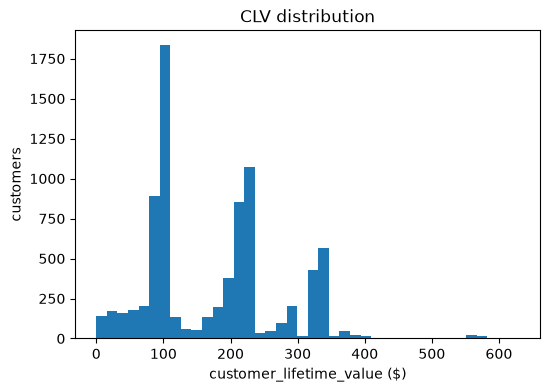

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBRegressor

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "processed").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

RANDOM_STATE = 42
df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "customer_features.csv")

print("rows:", len(df))
print(df["customer_lifetime_value"].describe().round(2))
print("skew:", round(df["customer_lifetime_value"].skew(), 3))

plt.figure(figsize=(6, 4))
plt.hist(df["customer_lifetime_value"], bins=40)
plt.xlabel("customer_lifetime_value ($)")
plt.ylabel("customers")
plt.title("CLV distribution")
plt.show()

I drop `avg_successful_payment_amount` because it is the mean of the same successful payments that add up to CLV. I drop `churned`, `churn_date`, and `churn_reason` so this model does not borrow the churn label. I drop `city` because 89 cities would blow up one-hot encoding; I already have `country`. I keep `customer_tenure_days` and `current_plan_name` on purpose.

In [2]:
target = "customer_lifetime_value"
drop_cols = [
    "customer_id",
    "registration_date",
    "churn_date",
    "churn_reason",
    "city",
    "churned",
    "avg_successful_payment_amount",
    target,
]

y = df[target]
X = df.drop(columns=drop_cols)
cat_cols = X.select_dtypes(include=["object", "bool"]).columns.tolist()
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print("train:", len(X_train), "test:", len(X_test))
print("numeric:", num_cols)
print("categorical:", cat_cols)

train: 6400 test: 1600
numeric: ['age', 'customer_tenure_days', 'avg_watch_time_per_session', 'monthly_watch_time_trend', 'days_since_last_activity', 'login_frequency', 'support_ticket_count', 'avg_customer_satisfaction', 'failed_payment_count', 'failed_payment_rate', 'plan_changes', 'engagement_score', 'feedback_count', 'avg_feedback_rating']
categorical: ['gender', 'country', 'acquisition_channel', 'customer_segment', 'preferred_language', 'current_plan_name']


Same idea as the churn notebook: a `ColumnTransformer` inside a `Pipeline`, fit on train folds only. CLV is a bit right-skewed, so I also try `log1p` as the training target and convert predictions back with `expm1`. Every score I report is in dollars, not in log dollars.

In [3]:
preprocess = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                ]
            ),
            num_cols,
        ),
        (
            "cat",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore")),
                ]
            ),
            cat_cols,
        ),
    ]
)

candidates = {
    "linear": LinearRegression(),
    "random_forest": RandomForestRegressor(
        n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "xgboost": XGBRegressor(
        n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1, verbosity=0
    ),
}


def make_estimator(model, log_target):
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    if log_target:
        return TransformedTargetRegressor(
            regressor=pipe, func=np.log1p, inverse_func=np.expm1
        )
    return pipe


cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2",
}

cv_rows = []
for log_target in [False, True]:
    scale = "log1p" if log_target else "raw"
    for name, model in candidates.items():
        est = make_estimator(model, log_target)
        scores = cross_validate(
            est, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1
        )
        row = {
            "model": name,
            "target_scale": scale,
            "mae": -scores["test_mae"].mean(),
            "rmse": -scores["test_rmse"].mean(),
            "r2": scores["test_r2"].mean(),
        }
        cv_rows.append(row)
        print(name, scale, {k: round(row[k], 3) if k == "r2" else round(row[k], 2) for k in ["mae", "rmse", "r2"]})

cv_table = pd.DataFrame(cv_rows).sort_values("mae")
display(cv_table.round(3))

linear raw {'mae': 29.3, 'rmse': 46.7, 'r2': 0.778}
random_forest raw {'mae': 10.79, 'rmse': 27.92, 'r2': 0.92}
xgboost raw {'mae': 12.23, 'rmse': 27.99, 'r2': 0.92}
linear log1p {'mae': 34.66, 'rmse': 50.42, 'r2': 0.741}
random_forest log1p {'mae': 9.9, 'rmse': 27.24, 'r2': 0.924}
xgboost log1p {'mae': 11.14, 'rmse': 27.72, 'r2': 0.921}


,model,target_scale,mae,rmse,r2
4,random_forest,log1p,9.896,27.237,0.924
1,random_forest,raw,10.791,27.916,0.920
5,xgboost,log1p,11.144,27.722,0.921
2,xgboost,raw,12.230,27.991,0.920
0,linear,raw,29.295,46.697,0.778
3,linear,log1p,34.659,50.425,0.741


I pick the lowest CV MAE, then score that setup on the held-out test set. I also score all six setups on test so I can put a three-model table in the write-up, with and without the log target.

,model,target_scale,mae,rmse,r2
4,random_forest,log1p,11.364,32.903,0.897
5,xgboost,log1p,11.375,31.872,0.903
1,random_forest,raw,12.387,33.385,0.894
2,xgboost,raw,12.624,32.890,0.897
0,linear,raw,30.425,51.082,0.751
3,linear,log1p,36.585,55.421,0.707


model I am taking forward: random_forest on log1p CLV
On average, my test predictions are off by about $11.36 against a mean CLV of $176.77.


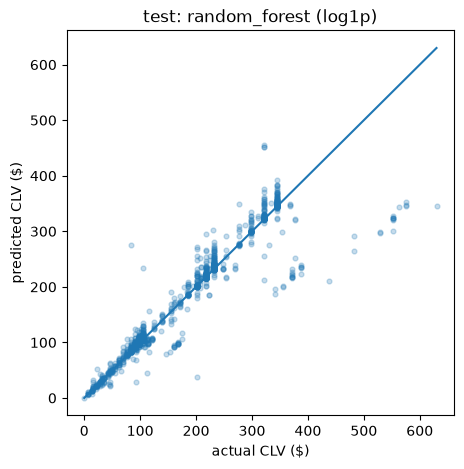

In [4]:
def regression_metrics(y_true, pred):
    return {
        "mae": mean_absolute_error(y_true, pred),
        "rmse": float(np.sqrt(mean_squared_error(y_true, pred))),
        "r2": r2_score(y_true, pred),
    }


test_rows = []
fitted = {}
for log_target in [False, True]:
    scale = "log1p" if log_target else "raw"
    for name, model in candidates.items():
        est = make_estimator(model, log_target)
        est.fit(X_train, y_train)
        pred = est.predict(X_test)
        fitted[(name, scale)] = (est, pred)
        row = {"model": name, "target_scale": scale, **regression_metrics(y_test, pred)}
        test_rows.append(row)

test_table = pd.DataFrame(test_rows).sort_values("mae")
display(test_table.round(3))

best = cv_table.iloc[0]
best_name = best["model"]
best_scale = best["target_scale"]
_, best_pred = fitted[(best_name, best_scale)]
best_test = regression_metrics(y_test, best_pred)

print("model I am taking forward:", best_name, "on", best_scale, "CLV")
print(
    f"On average, my test predictions are off by about ${best_test['mae']:.2f} "
    f"against a mean CLV of ${y_test.mean():.2f}."
)

plt.figure(figsize=(5, 5))
plt.scatter(y_test, best_pred, alpha=0.25, s=12)
lims = [0, max(y_test.max(), best_pred.max())]
plt.plot(lims, lims)
plt.xlabel("actual CLV ($)")
plt.ylabel("predicted CLV ($)")
plt.title(f"test: {best_name} ({best_scale})")
plt.show()

R² around 0.9 would worry me if I had passed in the payment total. I did not. Tenure and current plan are allowed to do a lot of the work, because CLV here is literally how long someone has paid and at what price. Linear Regression is clearly worse than the two tree models, which can pick up non-linear plan and tenure combinations. `log1p` helped the trees a little and hurt the linear model, so I am keeping the log target only if the table still says the trees win with it.